In [7]:
import pandas as pd
import time
import os
import urllib.request
import zipfile
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

# تحميل البيانات تلقائيًا في حال عدم وجودها لمنع الخطأ
file_name = "Dry_Bean_Dataset.xlsx"
if not os.path.exists(file_name):
    print("Downloading Dry Bean Dataset...")

    zip_path = "dry_bean_dataset.zip"
    urllib.request.urlretrieve(" zip_path")

    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(".")

    # نقل الملف المستخرج إلى المسار الرئيسي
    extracted_file_path = "DryBeanDataset/Dry_Bean_Dataset.xlsx"
    if os.path.exists(extracted_file_path):
        os.rename(extracted_file_path, file_name)
    print("Download and extraction completed!")

In [8]:
# 1. تحميل البيانات
df = pd.read_excel(file_name)
X = df.iloc[:, :-1]
y = LabelEncoder().fit_transform(df.iloc[:, -1])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# تطبيع البيانات لخوارزمية Adam
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [10]:
# Calculate and explain training and test ratios
total_samples = len(df)
train_samples = len(X_train)
test_samples = len(X_test)

train_percent = (train_samples / total_samples) * 100
test_percent = (test_samples / total_samples) * 100

print("=" * 50)
print("📊 Data Division Details (Train / Test Split):")
print("=" * 50)
print(f"🔹 Training ratio (Train Size): {train_percent:.1f}% ({train_samples:,} samples)")
print(f"🔸 Test ratio (Test Size)  : {test_percent:.1f}% ({test_samples:,} samples)")
print(f"🔹 Average sample : 100% ({total_samples:,} samples)")
print("=" * 50)

📊 Data Division Details (Train / Test Split):
🔹 Training ratio (Train Size): 80.0% (10,888 samples)
🔸 Test ratio (Test Size)  : 20.0% (2,723 samples)
🔹 Average sample : 100% (13,611 samples)


In [19]:
# 2. Random Forest Model Training and Evaluation
print("=" * 50)
print("🌲 Starting Random Forest Model training...")
print("=" * 50)

t0 = time.time()
rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_time = time.time() - t0
rf_pred = rf.predict(X_test)

# Verify Random Forest execution in English
print("🎉 Random Forest Model trained successfully!")
print("=" * 50)
print(f"⏱️ Training Time: {rf_time:.3f} seconds")
print(f"🎯 Number of predictions generated: {len(rf_pred):,}")
print(f"📊 First 10 predictions: {rf_pred[:10]}")
print("=" * 50)

🌲 Starting Random Forest Model training...
🎉 Random Forest Model trained successfully!
⏱️ Training Time: 7.040 seconds
🎯 Number of predictions generated: 2,723
📊 First 10 predictions: [3 1 6 5 0 5 3 6 2 4]


In [21]:
# 3. نموذج يعتمد على Adam Optimizer
print("=" * 50)
print("🧠 بدء تدريب نموذج الشبكة العصبية باستخدام Adam Optimizer...")
print("=" * 50)

t0 = time.time()
# تفعيل verbosity لمتابعة تطور عملية التدريب وتقليل الخطأ (Loss)
adam_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    solver='adam',
    learning_rate_init=0.001,
    max_iter=200,
    random_state=42,
    verbose=True
)

# بدء التدريب
adam_model.fit(X_train_scaled, y_train)
adam_time = time.time() - t0

# توليد التوقعات
adam_pred = adam_model.predict(X_test_scaled)

print("\n" + "=" * 50)
print("🎉 تم تدريب النموذج واختباره بنجاح!")
print("=" * 50)
print(f"⏱️ وقت التدريب: {adam_time:.3f} ثانية")
print(f"📉 قيمة الخسارة النهائية (Final Loss): {adam_model.loss_:.4f}")
print(f"🎯 أول 10 توقعات للنموذج: {adam_pred[:10]}")
print("=" * 50)

🧠 Starting Neural Network (Adam Optimizer) training...
Iteration 1, loss = 1.51475536
Iteration 2, loss = 0.63814642
Iteration 3, loss = 0.31576654
Iteration 4, loss = 0.24669915
Iteration 5, loss = 0.22542315
Iteration 6, loss = 0.21422323
Iteration 7, loss = 0.20928438
Iteration 8, loss = 0.20685952
Iteration 9, loss = 0.20178197
Iteration 10, loss = 0.20096949
Iteration 11, loss = 0.19775670
Iteration 12, loss = 0.19521079
Iteration 13, loss = 0.19376082
Iteration 14, loss = 0.19159703
Iteration 15, loss = 0.19180642
Iteration 16, loss = 0.19000492
Iteration 17, loss = 0.19070156
Iteration 18, loss = 0.18922007
Iteration 19, loss = 0.18637905
Iteration 20, loss = 0.18631136
Iteration 21, loss = 0.18630258
Iteration 22, loss = 0.18568542
Iteration 23, loss = 0.18479403
Iteration 24, loss = 0.18327492
Iteration 25, loss = 0.18210978
Iteration 26, loss = 0.18377806
Iteration 27, loss = 0.18183575
Iteration 28, loss = 0.18119903
Iteration 29, loss = 0.18089502
Iteration 30, loss = 0.179

           Model  Accuracy  Macro F1  Training Time (s)
0  Random Forest  0.919941  0.932108              8.497
1     Adam (MLP)  0.925083  0.937403              8.160


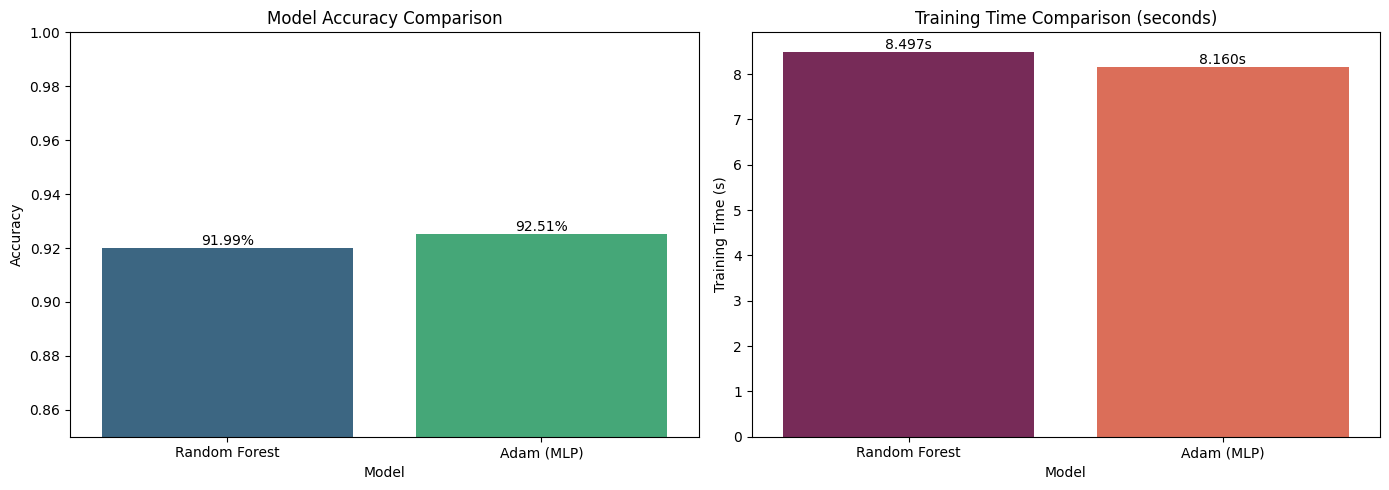

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

# 4. ملخص المقارنة
comparison = pd.DataFrame({
    "Model": ["Random Forest", "Adam (MLP)"],
    "Accuracy": [accuracy_score(y_test, rf_pred), accuracy_score(y_test, adam_pred)],
    "Macro F1": [f1_score(y_test, rf_pred, average='macro'), f1_score(y_test, adam_pred, average='macro')],
    "Training Time (s)": [round(rf_time, 3), round(adam_time, 3)]
})
print(comparison)

# رسم بياني للمقارنة بشكل نظيف وبدون تحذيرات
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# رسم الدقة (Accuracy)
sns.barplot(x="Model", y="Accuracy", data=comparison, ax=axes[0], hue="Model", legend=False, palette="viridis")
axes[0].set_title("Model Accuracy Comparison")
axes[0].set_ylim(0.85, 1.0) # لتوضيح الفروقات البسيطة بشكل أفضل
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height()*100:.2f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

# رسم وقت التدريب (Training Time)
sns.barplot(x="Model", y="Training Time (s)", data=comparison, ax=axes[1], hue="Model", legend=False, palette="rocket")
axes[1].set_title("Training Time Comparison (seconds)")
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.3f}s", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()